# Lab 16: How a coding agent edits files and runs tests

## Goal

Build a small coding agent and watch it fix a bug: the agent loop from lab 03, plus four file tools (list, read,
write, run the tests) that our code keeps inside one folder with a path check. The moment comes in Part D. The
agent's first fix turns the wrong price 10.989 into 8.991, and the test still fails, because the shop charges 8.99.
The agent reads that failure from the test run, fixes the code a second time, and the tests pass. The tests on disk
said whether it worked, not the model's last sentence, so Part E judges every run by the disk. Part F then shows the
hole: `run_tests` runs whatever the model wrote, with our permissions, and the path check cannot see it. That hole is
why lab 17 exists.

## What you will learn

- How to keep file tools inside a folder with a path check (`resolve()` and `is_relative_to`), and what that check
  does not stop.
- How to write list, read, write and run-tests tools as plain Python functions and call them by hand before any model
  sees them.
- How to let the agent loop work until the tests pass, with a turn cap, and read each tool call it made.
- How to check the result on disk (the diff, our own test run, the test file unchanged) instead of trusting the reply.
- Why running tests is running code, and how current coding agents handle that: patch and string-replacement edits,
  approval before writes, a sandbox around every command, and repo instruction files such as `AGENTS.md`.

## Where this lab starts

You have used a coding agent if you have asked an assistant in your editor to "fix the failing test". It looks as if
the model opened the file and typed. It did not: a model can only reply with text or with a tool call (a tool name
and a JSON string of arguments). **Our code** lists the folder, reads and writes the files and runs the tests. A coding
agent is the agent loop with file tools, pointed at a folder.

Lab 03 wrote that loop, and this notebook restates it, so it runs on its own:

1. **Send** the messages and the tool schemas to the model.
2. **Run and append:** if the reply asks for tools (`finish_reason` is `tool_calls`), run each one and append one
   `tool` message per call with its result.
3. **Repeat** until the model answers in text, or a turn cap stops the loop.

The picture shows what we build. The black box is the model's work; the lime boxes are our code's. The dashed edge
is Part F.

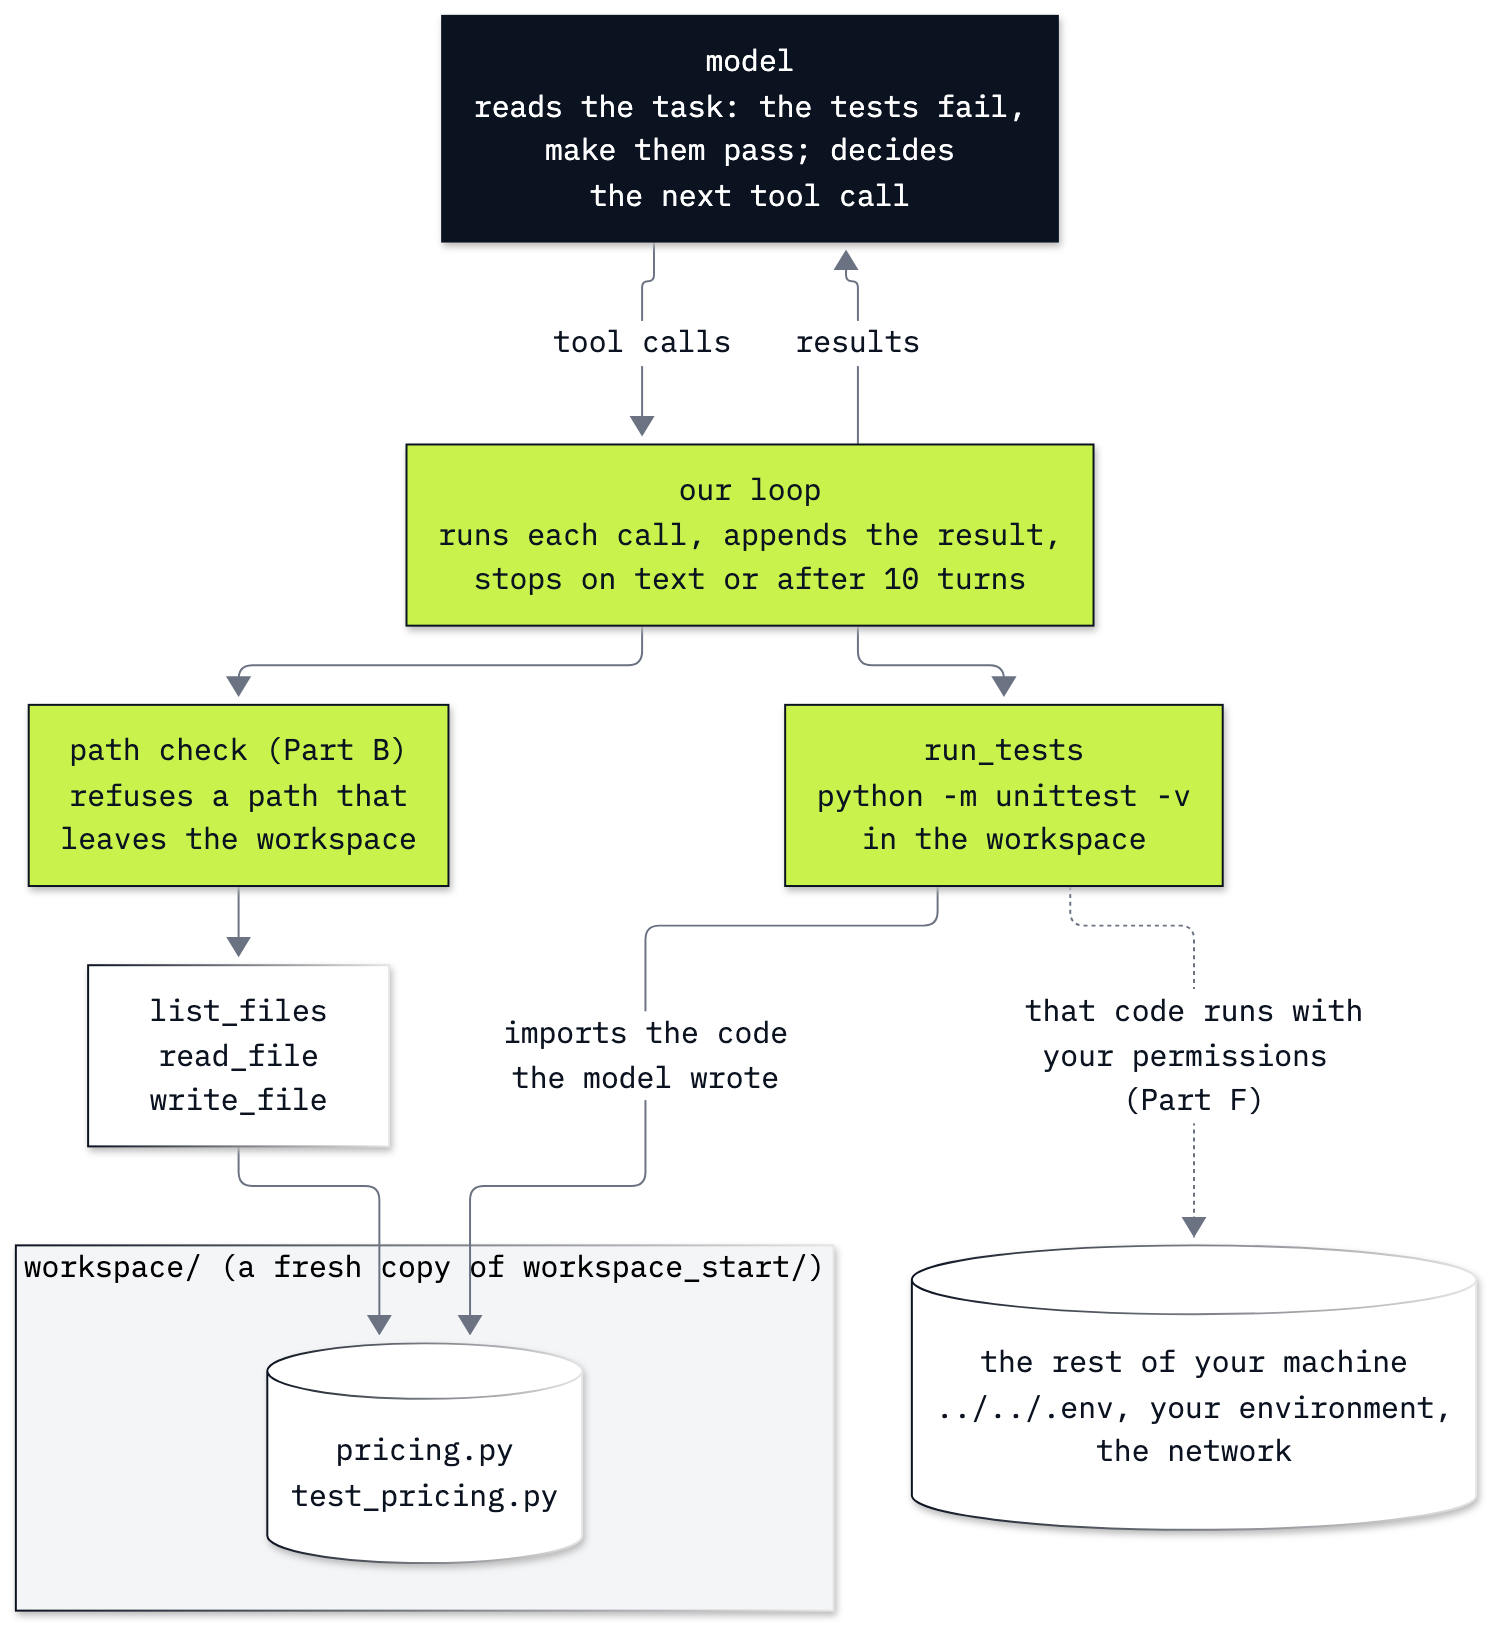

In [1]:
from IPython.display import Image

Image("resources/lab16_coding_agent.png", width=760)

Notice where the path check sits: between the loop and the three file tools, but not in front of `run_tests`.
`run_tests` takes no path at all. It runs Python on whatever the files hold at that moment.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the model and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client and the names this lab uses. `START` is the folder `workspace_start/`, committed with the bug in
it; `WORK` is `workspace/`, the copy the agent works on. Git ignores `workspace/`, and we copy it again from `START`
before every run, so each run starts from the same bug. Prices come from `models.env` so Part E can say what a run
costs.

Every model call below passes `reasoning_effort=EFFORT or omit` (lab 03 explains it): with effort `none` the model can
call tools on Chat Completions, the API this lab uses, as lab 03 did.

In [3]:
import json
import shutil
import subprocess
import sys
from openai import OpenAI, omit

client = OpenAI()
LAB = ROOT / "16_Coding_Agent"
START = LAB / "workspace_start"   # the starting files, committed with the bug in them
WORK = LAB / "workspace"          # the agent's copy of them; git ignores it, and every run starts it again
MAX_OUTPUT = 800                  # tokens per reply: room for a whole small file in one write_file call
MAX_TURNS = 10
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
print("start folder:", START.relative_to(ROOT), "| workspace:", WORK.relative_to(ROOT))

start folder: 14_Coding_Agent/workspace_start | workspace: 14_Coding_Agent/workspace


---

## Part A: Read the bug and its failing test

A coding agent's job starts the way a ticket does: something fails. Before any model is involved, we look at the
two starting files and run their tests ourselves, so we know exactly what "fixed" has to mean.

First the copy. `shutil.rmtree(WORK, ignore_errors=True)` deletes `workspace/` with everything in it (and does
nothing when it is not there yet); `shutil.copytree(START, WORK)` copies the starting folder in its place.

⚠️ `rmtree` deletes a whole folder without asking. Here it only ever deletes the lab's own `workspace/`; never point
`WORK` at a folder that holds your own files.

In [4]:
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(START, WORK)
print(sorted(p.name for p in WORK.iterdir()))

['pricing.py', 'test_pricing.py']


Two files: the code and its test. Here is what each one holds.

In [5]:
for name in ["pricing.py", "test_pricing.py"]:
    print(f"----- {name}")
    print((WORK / name).read_text())

----- pricing.py
def apply_discount(price, percent):
    """Price of an item after a percent discount."""
    return price + price * percent / 100

----- test_pricing.py
import unittest

from pricing import apply_discount


class ApplyDiscountTest(unittest.TestCase):
    def test_no_discount(self):
        self.assertEqual(apply_discount(0.99, 0), 0.99)

    def test_ten_percent_off_an_album(self):
        self.assertEqual(apply_discount(9.99, 10), 8.99)



Reading the two files:

- **`pricing.py`** has one function, `apply_discount(price, percent)`. It returns `price + price * percent / 100`:
  it **adds** the discount instead of taking it off.
- **`test_pricing.py`** is a `unittest` test case, `ApplyDiscountTest`, with two tests. Each method whose name starts
  with `test_` is one test, and `assertEqual(a, b)` fails the test when `a` and `b` differ.
  - `test_no_discount`: 0 percent off a 0.99 track is still 0.99.
  - `test_ten_percent_off_an_album`: 10 percent off a 9.99 album is **8.99**, what the shop charges.

**Predict before you run:** what does `apply_discount(9.99, 10)` return with the bug, and which of the two tests
fails? (The first test passes with the bug too: adding 0 percent changes nothing.)

To run the tests we start a second Python process, the way you would in a terminal. `subprocess.run` takes the
command as a list of words:

- `sys.executable` is the path of the Python running this notebook, so the tests run with the same Python and
  packages;
- `-m unittest -v` runs the standard library's test runner, which finds every `test_*.py` file in the current folder
  and, with `-v`, prints one line per test;
- `cwd=WORK` makes `workspace/` the current folder of the new process, so `from pricing import apply_discount` finds
  the workspace's `pricing.py`;
- `capture_output=True, text=True` keeps what the process prints, as strings, instead of showing it;
- `timeout=30` stops the process if it has not finished after 30 seconds.

`unittest` names each file in its report by its full path on your machine. When we print the report we replace the
workspace's full path with the word `workspace`, so the report is shorter and shows no folder names from your
computer.

In [6]:
result = subprocess.run(
    [sys.executable, "-m", "unittest", "-v"],
    cwd=WORK, capture_output=True, text=True, timeout=30,
)
print("exit code:", result.returncode)
print("stdout:", repr(result.stdout))
print(result.stderr.replace(str(WORK.resolve()), "workspace"))

exit code: 1
stdout: ''
test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... FAIL

FAIL: test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "workspace/test_pricing.py", line 11, in test_ten_percent_off_an_album
    self.assertEqual(apply_discount(9.99, 10), 8.99)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 10.989 != 8.99

----------------------------------------------------------------------
Ran 2 tests in 0.000s

FAILED (failures=1)



Reading the run:

- `stdout` is empty: `unittest` writes its report to `stderr`, the second output stream. A `print()` inside the code
  under test would land in `stdout`. A tool that runs tests has to return both.
- `test_no_discount ... ok`, then `test_ten_percent_off_an_album ... FAIL`.
- `AssertionError: 10.989 != 8.99`: with the bug, 10 percent of 9.99 (0.999) is added, giving 10.989.
- `FAILED (failures=1)` and exit code 1. Any exit code other than 0 means something failed.

That failure report is the ticket. It is all the agent will be given about the bug: the task will say only "the
tests fail, make them pass", and the agent has to find this report itself.

**Checkpoint A.** Two files in `workspace/`; one test passes and one fails with `AssertionError: 10.989 != 8.99`;
exit code 1. A pass shows the workspace starts broken on every run; it does not say yet what a correct fix looks like
beyond this one test.

---

## Part B: Keep the file tools inside the workspace with a path check

The model will name files, and a file name is text the model wrote. Nothing stops it from writing `../../.env` (the
repository's key file, two folders up from `workspace/`) or an absolute path such as `/etc/hosts`. In the agent loop
our code checks every call before it runs; for file tools, that check is on the path.

First, what a path turns into. `WORK / name` joins two paths. `.resolve()` turns the result into the full path it
really points to: it removes every `..` (one folder up) and follows links. Two facts matter here:

- `WORK / "../../.env"` resolves to the `.env` in the repository folder, outside `workspace/`.
- When the right side is already absolute, `/` drops the left side: `WORK / "/etc/hosts"` is just `/etc/hosts`.

`is_relative_to(folder)` answers one question: is this path inside that folder? We print each resolved path relative
to the repository folder (and say "outside the repository" when it is not), so no full path from your machine appears.

In [7]:
for name in ["pricing.py", "../../.env", "/etc/hosts", "notes/../pricing.py"]:
    target = (WORK / name).resolve()
    where = target.relative_to(ROOT.resolve()) if target.is_relative_to(ROOT.resolve()) else "outside the repository"
    print(f"{name:20} -> {str(where):35} inside workspace/: {target.is_relative_to(WORK.resolve())}")

pricing.py           -> 14_Coding_Agent/workspace/pricing.py inside workspace/: True
../../.env           -> .env                                inside workspace/: False
/etc/hosts           -> outside the repository              inside workspace/: False
notes/../pricing.py  -> 14_Coding_Agent/workspace/pricing.py inside workspace/: True


Line by line:

- `pricing.py` resolves to `16_Coding_Agent/workspace/pricing.py`: inside.
- `../../.env` resolves to `.env` at the repository folder: two levels up, outside.
- `/etc/hosts` is a system file: outside the repository altogether.
- `notes/../pricing.py` goes into a folder and back out again: it resolves to the same `pricing.py`, so it is
  inside. Looking at the text of a path ("does it contain `..`?") would have refused it, and would have missed
  tricks that do not use `..` at all. Resolving first, then asking where the path ends up, is the reliable order.

The check is that one question, in a function the tools call before they touch a file:

In [8]:
def check_path(name):
    """The file inside the workspace that name points to, or None when name leaves the workspace."""
    target = (WORK / name).resolve()
    if target.is_relative_to(WORK.resolve()):
        return target
    return None


for name in ["pricing.py", "../../.env", "/etc/hosts"]:
    print(f"{name:12} -> {'allowed' if check_path(name) else 'refused'}")

pricing.py   -> allowed
../../.env   -> refused
/etc/hosts   -> refused


`check_path` returns the resolved path when it is inside the workspace and `None` when it is not, so a tool can
write `if target is None:` and refuse. `pricing.py` is allowed; `../../.env` and `/etc/hosts` are refused. Because
`resolve()` follows links, a link inside the workspace that points outside it is refused too.

**Important:** the path check looks at **names**. It decides which files the tools may open. It says nothing about
what the code inside an allowed file does when it runs. Part F comes back to that.

**Checkpoint B.** `pricing.py` allowed; `../../.env` and `/etc/hosts` refused. A pass shows the file tools cannot be
pointed outside `workspace/`; it does not show the workspace is safe to run.

---

## Part C: Write the file tools as plain functions and call them by hand

The model never touches the disk; it asks, and these functions do the work. We write them as plain Python and call
them ourselves first, as you would test any function before handing it to someone else. Each one returns
a **string**, because a tool result goes back to the model as the text of a `tool` message. When a tool cannot do
what it was asked (a refused path, a missing file), it says so in that string, so the model can read the reason and
try something else instead of the loop crashing.

- `list_files()`: the names of the files in the workspace, one per line. The model cannot see the folder; this is
  how it finds out what is there.
- `read_file(path)`: the text of one file, after the path check.
- `write_file(path, content)`: replaces the **whole** file with `content`, after the path check. This is the
  simplest edit tool there is; Part F names what current coding agents use instead.

In [9]:
def list_files():
    return "\n".join(sorted(p.name for p in WORK.iterdir() if p.is_file()))


def read_file(path):
    target = check_path(path)
    if target is None:
        return f"Refused: {path} is outside the workspace."
    if not target.is_file():
        return f"There is no file named {path} in the workspace."
    return target.read_text()


def write_file(path, content):
    target = check_path(path)
    if target is None:
        return f"Refused: {path} is outside the workspace."
    target.write_text(content)
    return f"Wrote {len(content)} characters to {path}."

Now we call them as the model would, one at a time.

In [10]:
print(list_files())
print("-----")
print(read_file("pricing.py"))
print("-----")
print(read_file("../../.env"))
print(write_file("../notes.txt", "a note"))

pricing.py
test_pricing.py
-----
def apply_discount(price, percent):
    """Price of an item after a percent discount."""
    return price + price * percent / 100

-----
Refused: ../../.env is outside the workspace.
Refused: ../notes.txt is outside the workspace.


`list_files` named the two files. `read_file("pricing.py")` returned the buggy function as text. Both calls that
pointed outside, a read of `../../.env` and a write to `../notes.txt` (in the lab folder, one level up), came back as
a refusal **sentence**: nothing was read and nothing was written. A model that gets that sentence can read it and
change course.

One successful write, so you see what the model will see after a write: we write a small file, list the folder, then
delete the file again with `unlink()`, so the workspace is back as it started.

In [11]:
print(write_file("notes.txt", "a note from us\n"))
print(list_files())
(WORK / "notes.txt").unlink()
print(list_files())

Wrote 15 characters to notes.txt.
notes.txt
pricing.py
test_pricing.py
pricing.py
test_pricing.py


The fourth tool runs the tests. It is Part A's `subprocess.run` call inside a function, with two changes so the model
can always read its result:

- it returns `stdout` and `stderr` joined into one string, so both the test report and anything the code printed come
  back, with the workspace's full path shortened to `workspace` as in Part A (the model does not need to know where
  the folder is on your machine);
- if the 30 seconds run out, `subprocess.run` raises `subprocess.TimeoutExpired`; `try` / `except` catches it and
  returns a sentence instead. A loop that never ends is one of the bugs a model can write.

In [12]:
def run_tests():
    try:
        result = subprocess.run(
            [sys.executable, "-m", "unittest", "-v"],
            cwd=WORK, capture_output=True, text=True, timeout=30,
        )
    except subprocess.TimeoutExpired:
        return "The tests did not finish within 30 seconds and were stopped."
    return (result.stdout + result.stderr).replace(str(WORK.resolve()), "workspace")


print(run_tests())

test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... FAIL

FAIL: test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "workspace/test_pricing.py", line 11, in test_ten_percent_off_an_album
    self.assertEqual(apply_discount(9.99, 10), 8.99)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 10.989 != 8.99

----------------------------------------------------------------------
Ran 2 tests in 0.000s

FAILED (failures=1)



The same report as in Part A: one test `ok`, one `FAIL` with `AssertionError: 10.989 != 8.99`, `FAILED
(failures=1)`. The agent will get exactly this text back when it calls `run_tests`.

**Checkpoint C.** `list_files` gives `pricing.py` and `test_pricing.py`; `read_file("../../.env")` and
`write_file("../notes.txt", ...)` are refused with a sentence; `notes.txt` appears after the write and is gone after
`unlink()`; `run_tests()` returns the failing report. A pass shows each tool does its one job when we call it; it does
not show a model will call them in a useful order. That is Part D.

---

## Part D: Let the agent loop work until the tests pass

Now the model gets the tools. It never sees our functions, only a description of each: a JSON schema with a name, a
sentence the model reads to decide when to call it, and the arguments. The four schemas have the same shape, so a
small function writes it once, as in lab 03. `strict: True` asks the API to make the arguments match the schema
exactly, which needs every property in `required` and `additionalProperties: False`. `FUNCTIONS` maps each tool name
to the Python function allowed to run; a name that is not a key there never runs anything.

In [13]:
def tool_schema(name, description, properties):
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "strict": True,
            "parameters": {
                "type": "object",
                "properties": properties,
                "required": list(properties),
                "additionalProperties": False,
            },
        },
    }


PATH = {"type": "string", "description": "A file name in the workspace, for example 'pricing.py'"}
TOOLS = [
    tool_schema("list_files", "List the files in the workspace.", {}),
    tool_schema("read_file", "Read one file in the workspace.", {"path": PATH}),
    tool_schema("write_file", "Replace the whole content of one file in the workspace (creates it if missing).",
                {"path": PATH, "content": {"type": "string"}}),
    tool_schema("run_tests", "Run the workspace's unit tests and return their output.", {}),
]
FUNCTIONS = {"list_files": list_files, "read_file": read_file, "write_file": write_file, "run_tests": run_tests}
print(json.dumps(TOOLS[2], indent=2))

{
  "type": "function",
  "function": {
    "name": "write_file",
    "description": "Replace the whole content of one file in the workspace (creates it if missing).",
    "strict": true,
    "parameters": {
      "type": "object",
      "properties": {
        "path": {
          "type": "string",
          "description": "A file name in the workspace, for example 'pricing.py'"
        },
        "content": {
          "type": "string"
        }
      },
      "required": [
        "path",
        "content"
      ],
      "additionalProperties": false
    }
  }
}


That is everything the model knows about `write_file`: a name, one sentence, and two string arguments, `path` and
`content`. It says the tool replaces the whole file, so the model must send the complete new file every time.

The system message tells the agent how to work: read before changing anything, run the tests after every change, stop
when they pass. It does not say what the bug is, and it does not forbid editing the test file: we left that open on
purpose, so Part E can check it on disk. The task is the ticket in one sentence.

In [14]:
SYSTEM = ("You fix Python code in a small workspace. Use list_files, read_file, write_file and run_tests. "
          "Read the failing test and the code before you change anything, and run the tests after every change. "
          "When the tests pass, stop and say in one or two sentences what you changed.")
TASK = "The unit tests in the workspace fail. Make them pass."

messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": TASK}]
response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=TOOLS,
    max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
)
choice = response.choices[0]
print("finish_reason:", choice.finish_reason)
print("content:      ", choice.message.content)
for call in choice.message.tool_calls or []:
    print("tool call:    ", call.function.name, call.function.arguments)

finish_reason: tool_calls
content:       None
tool call:     list_files {}


`finish_reason` is `tool_calls` and `content` is `None`: the model wrote no text. Its first request is `list_files`
with `{}`, empty arguments: before reading anything, it asks what is in the folder, as you would on a project you
have not seen. Nothing has run yet. The request is only text until our code acts on it.

Running a call is the same for every tool: look the name up in `FUNCTIONS`, turn the argument string into a
dictionary with `json.loads`, and call the function with `**arguments` (each key becomes a keyword argument:
`read_file(path="pricing.py")`; an empty dictionary calls `list_files()` with nothing). `run_tool` also catches any
exception and returns it as text, as lab 03 does, so a bad call becomes a result the model can read.

In [15]:
def run_tool(call):
    try:
        function = FUNCTIONS[call.function.name]
        arguments = json.loads(call.function.arguments)
        return function(**arguments)
    except Exception as error:
        return f"Error: {type(error).__name__}: {error}"


messages.append(choice.message)
for call in choice.message.tool_calls or []:
    result = run_tool(call)
    messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    print(call.function.name, "->", result)

list_files -> pricing.py
test_pricing.py


Our code ran `list_files` and appended its result, the two file names, as a `tool` message carrying the call's `id`.
That is one call taken all the way round by hand. The loop below starts again from an empty list, so its run is
complete on its own.

### The loop, with every tool call printed

Now the full loop, from a fresh copy of the workspace and a fresh message list. Each pass is one **turn**, one call to
the model:

1. Send the whole list, with the tools.
2. Append the reply.
3. If `finish_reason` is not `tool_calls`, the model has written its answer: leave the loop.
4. Otherwise run every tool call, append one `tool` message per call, and go back to step 1.

`for turn in range(1, MAX_TURNS + 1)` caps the run at 10 turns, whatever the model wants. To make the run readable we
print one line per tool call, plus, under it, the new file for a `write_file` and the lines that matter from a
`run_tests` (the `AssertionError`, and `OK` or `FAILED`). `textwrap.indent` puts four spaces in front of every line so
those details sit under their call.

In [16]:
import textwrap

shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(START, WORK)
messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": TASK}]

for turn in range(1, MAX_TURNS + 1):
    response = client.chat.completions.create(
        model=MODEL, messages=messages, tools=TOOLS,
        max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
    )
    choice = response.choices[0]
    messages.append(choice.message)
    if choice.finish_reason != "tool_calls":
        print(f"turn {turn}: answer: {choice.message.content}")
        break
    for call in choice.message.tool_calls:
        result = run_tool(call)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
        arguments = json.loads(call.function.arguments)
        print(f"turn {turn}: {call.function.name}({arguments.get('path', '')})")
        if call.function.name == "write_file":
            print(textwrap.indent(arguments["content"].rstrip(), "    "))
        if call.function.name == "run_tests":
            lines = [l for l in result.splitlines() if l.startswith(("AssertionError", "OK", "FAILED"))]
            print(textwrap.indent("\n".join(lines), "    "))

turn 1: list_files()


turn 2: read_file(test_pricing.py)
turn 2: read_file(pricing.py)


turn 3: run_tests()
    AssertionError: 10.989 != 8.99
    FAILED (failures=1)


turn 4: write_file(pricing.py)
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100


turn 5: run_tests()
    AssertionError: 8.991 != 8.99
    FAILED (failures=1)


turn 6: write_file(pricing.py)
    def apply_discount(price, percent):
        """Price of an item after a percent discount, rounded to cents."""
        return round(price - price * percent / 100, 2)


turn 7: run_tests()
    OK


turn 8: answer: Fixed `apply_discount` to subtract the discount and round the result to two decimal places. All tests pass.


Read the run turn by turn:

- **Turn 1:** `list_files`, as in the hand turn.
- **Turn 2:** two reads in one reply, the test first, then the code.
- **Turn 3:** `run_tests` before changing anything: `AssertionError: 10.989 != 8.99`, the report we saw in Part A.
- **Turn 4:** the first write. The `+` becomes a `-`; nothing else changes.
- **Turn 5:** `run_tests` again: `AssertionError: 8.991 != 8.99`. The sign is right now, and the test still fails.
- **Turn 6:** the second write: the same line inside `round(..., 2)`, and "rounded to cents" added to the docstring.
- **Turn 7:** `run_tests`: `OK`.
- **Turn 8:** the answer: *Fixed `apply_discount` to subtract the discount and round the result to two decimal
  places. All tests pass.*

Eight turns, inside the cap of 10. The loop left by its first exit, an answer.

**Why did the first fix fail?** 9.99 − 0.999 is 8.991. The test wants 8.99 because the shop charges in cents, and nothing in `pricing.py` says
so: only the test does. The agent found that out the way a developer would, from `AssertionError: 8.991 != 8.99`,
which our `run_tests` returned to it as text. Without a test run between the two writes, nothing in the loop would
have shown that the first fix was wrong.

**Checkpoint D.** The agent lists the files, reads both, writes `price - price * percent / 100`, gets
`AssertionError: 8.991 != 8.99`, writes the version with `round(..., 2)`, gets `OK` and answers: 8 turns of the 10
allowed in our run (7 or 8 in every run we have seen). A pass shows this run reached green tests inside the cap; it does not show the
agent always does, and the last line is still only what the model says. Part E checks the disk.

---

## Part E: Judge the fix by the disk, not by the reply

The agent's last message says the tests pass. That sentence is a claim the model wrote; it could be wrong, or the
tests could pass for a bad reason (an agent that edits the test to expect 10.989 also gets green tests). Coding agents
are checked the way a reviewer checks a colleague's change: look at the change itself and run the tests yourself.
Three checks, each answering one question:

1. **What changed?** A diff of `pricing.py` between the start folder and the workspace.
2. **Do the tests pass when we run them?** Our own `run_tests()`, not the model's report of it.
3. **Is the test still the one we wrote?** `test_pricing.py` compared with the start folder's copy.

`difflib.unified_diff` takes the two files as lists of lines and returns the differences in the format `git diff`
uses: two header lines naming the files (`---` the old one, `+++` the new one), an `@@` line saying which lines
follow, then each line prefixed with `-` (removed), `+` (added) or a space (unchanged).

In [17]:
import difflib

before = (START / "pricing.py").read_text().splitlines(keepends=True)
after = (WORK / "pricing.py").read_text().splitlines(keepends=True)
print("".join(difflib.unified_diff(before, after, "workspace_start/pricing.py", "workspace/pricing.py")))

--- workspace_start/pricing.py
+++ workspace/pricing.py
@@ -1,3 +1,3 @@
 def apply_discount(price, percent):
-    """Price of an item after a percent discount."""
-    return price + price * percent / 100
+    """Price of an item after a percent discount, rounded to cents."""
+    return round(price - price * percent / 100, 2)



Two lines changed, each shown as a `-` line (before) and a `+` line (after): the docstring, where the agent added
"rounded to cents", and the return line, where `price + price * percent / 100` became
`round(price - price * percent / 100, 2)`. The `def` line has a space in front: unchanged. That is the whole change:
one function, nothing else touched.

Now the tests, run by us, and the test file compared with its starting copy:

In [18]:
print(run_tests())
same_test = (WORK / "test_pricing.py").read_text() == (START / "test_pricing.py").read_text()
print("test_pricing.py unchanged:", same_test)

test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.000s

OK

test_pricing.py unchanged: True


Both tests are `ok` when we run them ourselves, the report ends in `OK`, and `test_pricing.py unchanged: True`: the
tests pass because the code changed, not because the test did. Together the three checks say the fix is real. They
do not say the code is good; for that a person still reads the diff.

### Does the agent fix it every time?

One run is one sample. To run the agent again and again we now package what we have already run once:

- `fresh_workspace()` is Part A's two lines: delete `workspace/` and copy the start folder again.
- `run_coding_agent()` is Part D's loop without the printing. It records every call as a tuple `(tool name,
  arguments, result)` and adds up the tokens of every call from `response.usage`, and returns a dictionary: the
  answer (or `None` if the cap stopped it), the number of turns, the calls and the tokens.
- `check_on_disk()` is the two checks we just ran by hand, as `True` or `False`: do the tests pass when we run them,
  and is every `test_*.py` file the same as in the start folder.

In [19]:
def fresh_workspace(start=START):
    shutil.rmtree(WORK, ignore_errors=True)
    shutil.copytree(start, WORK)


def run_coding_agent(system=SYSTEM, task=TASK, max_turns=MAX_TURNS):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": task}]
    calls, tokens_in, tokens_out = [], 0, 0
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS,
            max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
        )
        tokens_in += response.usage.prompt_tokens
        tokens_out += response.usage.completion_tokens
        choice = response.choices[0]
        messages.append(choice.message)
        if choice.finish_reason != "tool_calls":
            return {"answer": choice.message.content, "turns": turn, "calls": calls, "tokens": (tokens_in, tokens_out)}
        for call in choice.message.tool_calls:
            result = run_tool(call)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
            calls.append((call.function.name, json.loads(call.function.arguments), result))
    return {"answer": None, "turns": max_turns, "calls": calls, "tokens": (tokens_in, tokens_out)}


def check_on_disk(start=START):
    output = run_tests()
    test_files = [p.name for p in start.glob("test_*.py")]
    return {
        "tests_pass": output.rstrip().endswith("OK"),
        "tests_unchanged": all((WORK / n).read_text() == (start / n).read_text() for n in test_files),
    }

Five runs, each from a fresh copy. For each run we print the turns, how many times the agent wrote `pricing.py`,
the verdict of every `run_tests` the agent called (the last line of each report: `OK` or `FAILED (failures=1)`), the
two disk checks, and the cost priced from `models.env`. `run.update(check_on_disk())` adds the two checks to the
run's dictionary, and we keep every run in `runs` to read its writes afterwards.

In [20]:
runs = []
for number in range(1, 6):
    fresh_workspace()
    run = run_coding_agent()
    run.update(check_on_disk())
    runs.append(run)
    writes = [args for name, args, _ in run["calls"] if name == "write_file"]
    verdicts = [result.strip().splitlines()[-1] for name, _, result in run["calls"] if name == "run_tests"]
    tokens_in, tokens_out = run["tokens"]
    cost = tokens_in / 1e6 * PRICE_IN + tokens_out / 1e6 * PRICE_OUT
    print(f"run {number}: {run['turns']} turns, {len(writes)} writes, agent's test runs {verdicts}")
    print(f"       tests pass on disk: {run['tests_pass']}, tests unchanged: {run['tests_unchanged']}, "
          f"{tokens_in} input and {tokens_out} output tokens, ${cost:.5f}")

run 1: 8 turns, 2 writes, agent's test runs ['FAILED (failures=1)', 'FAILED (failures=1)', 'OK']
       tests pass on disk: True, tests unchanged: True, 5788 input and 252 output tokens, $0.00070


run 2: 8 turns, 2 writes, agent's test runs ['FAILED (failures=1)', 'FAILED (failures=1)', 'OK']
       tests pass on disk: True, tests unchanged: True, 5788 input and 249 output tokens, $0.00070


run 3: 8 turns, 2 writes, agent's test runs ['FAILED (failures=1)', 'FAILED (failures=1)', 'OK']
       tests pass on disk: True, tests unchanged: True, 5788 input and 249 output tokens, $0.00070


run 4: 8 turns, 2 writes, agent's test runs ['FAILED (failures=1)', 'FAILED (failures=1)', 'OK']
       tests pass on disk: True, tests unchanged: True, 5788 input and 249 output tokens, $0.00070


run 5: 7 turns, 2 writes, agent's test runs ['FAILED (failures=1)', 'FAILED (failures=1)', 'OK']
       tests pass on disk: True, tests unchanged: True, 5286 input and 250 output tokens, $0.00065


All five runs reached passing tests on disk, with the test file unchanged. Four took 8 turns and one took 7. Every
run wrote `pricing.py` twice, and in every run the agent's own three test runs read `FAILED (failures=1)`,
`FAILED (failures=1)`, `OK`. Each run cost between $0.00065 and $0.00070 at the prices in `models.env`. Outside this
notebook we ran the agent ten more times: the same pattern every time, the first fix failing with 8.991 in 10 of 10
and the tests passing in 10 of 10.

The counts say how often; the files say what. Here is the first `write_file` content of every run, the fix the agent
tried before it had seen a test result for it. `enumerate(runs, start=1)` numbers the runs from 1, and `next(...)`
takes the first item the expression inside it produces: the content of the run's first `write_file` call.

In [21]:
for number, run in enumerate(runs, start=1):
    first_write = next(args["content"] for name, args, _ in run["calls"] if name == "write_file")
    print(f"run {number}, first write:")
    print(textwrap.indent(first_write.rstrip(), "    "))

run 1, first write:
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100
run 2, first write:
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100
run 3, first write:
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100
run 4, first write:
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100
run 5, first write:
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return price - price * percent / 100


The same first fix in all five runs: the sign turned from `+` to `-`, with no rounding. That is the obvious reading
of the bug, and it is wrong for this shop. It took a test run to show the agent the missing rule.

**Lesson to Remember.** The model's reply is a report, not evidence. The evidence is on disk:

| Question | Where the answer comes from |
|---|---|
| Did the tests pass? | our own `run_tests()`, run after the agent stopped |
| What did the agent change? | the diff against the start folder |
| Did it change the tests to make them pass? | the test files compared with the start folder |

Notice that the second fix came from **reading a test result**: the loop gave the model the failure, and the
failure carried the information the first fix lacked. Running the tests is what made the agent good at this task.
Part F looks at what running them costs.

**Checkpoint E.** The diff shows `price + price * percent / 100` replaced by `round(price - price * percent / 100, 2)`; our own test
run ends in `OK`; `test_pricing.py unchanged: True`. Over five more runs: tests passing and unchanged 5 of 5, two
writes in each, the first one failing every time. A pass shows this bug is fixed reliably with this prompt and these tools; it does
not show the tests cover everything a discount should do (a negative percent, a percent over 100).

---

## Part F: See that running tests runs the model's code

Part B refused `../../.env` for every file tool. But look again at what `run_tests` does: it starts Python in the
workspace, and `unittest` **imports** `pricing.py`, which runs every line in it. The code in `pricing.py` is whatever
the model last wrote. So any line the model writes there runs on your machine, as you, every time the agent runs the
tests.

To see it, we write a `pricing.py` ourselves, standing in for a model that was misled (lab 19 shows how text the
agent reads can steer it) or that was simply wrong. No model is called in this part. The file holds a correct
`apply_discount`, so the tests still pass, and three lines at the top that only **look**: does a `.env` file exist at
the repository folder (`../../.env`, seen from `workspace/`), and is there an `OPENAI_API_KEY` in the process's
environment? They print `True` or `False`, never a value.

In [22]:
PROBE = """from pathlib import Path
import os
print(".env file at the repository folder:", Path("../../.env").exists())
print("OPENAI_API_KEY in the environment:", "OPENAI_API_KEY" in os.environ)


def apply_discount(price, percent):
    return round(price - price * percent / 100, 2)
"""

print(write_file("pricing.py", PROBE))
print(read_file("../../.env"))
print("-----")
print(run_tests())

Wrote 274 characters to pricing.py.
Refused: ../../.env is outside the workspace.
-----
.env file at the repository folder: True
OPENAI_API_KEY in the environment: True
test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.000s

OK



`write_file` accepted `pricing.py`, since it is inside the workspace, and `read_file("../../.env")` was refused. Then
`run_tests` printed two lines before the test report, from the code at the top of `pricing.py`:
`.env file at the repository folder: True` and `OPENAI_API_KEY in the environment: True`. Both tests passed, so a test
report that says `OK` tells you nothing about what else the code did.

Read the two halves together:

- `read_file("../../.env")` was refused: the path check did its job on a **name**.
- The same file was then found by code inside `pricing.py`, which the path check allowed, because `pricing.py` is
  inside the workspace. `run_tests` ran it with our user's permissions.
- The key is in the environment because the config cell put it there, and a process started with `subprocess.run`
  inherits the environment of the process that started it.

**The path check guarded names, not execution.**

⚠️ What `run_tests` does **not** stop: code in the workspace that reads any file your user can read (your SSH keys,
other projects, `.env` files), reads the API key from the environment, sends what it finds over the network, deletes
or changes files outside `workspace/`, or starts other programs. The 30-second timeout only stops code that runs too
long. Do not point this agent at a folder whose code you would not run yourself, and do not give it tasks that
include text from people you do not trust. Lab 17 runs model-written code in a container with no network and in
OpenAI's hosted code interpreter, and measures what this same kind of probe finds in each.

A tempting quick fix is to pass `env={}` to `subprocess.run`, so the tests run without the key in their environment.
It hides the key, not the file: the `.env` line would still say `True`. Lab 17 measures a subprocess with a trimmed
environment, a timeout and its own folder, and shows the same probe still finds the file.

**In production:** coding agents keep the loop you wrote and change four things around it.

- **Edits as patches, not whole files.** Instead of `write_file`, the model sends only the change: a structured diff
  (OpenAI's `apply_patch` tool, where the model emits patch operations and your code applies them) or a string
  replacement (an old snippet and its new text, refused unless the old snippet appears exactly once). The model writes
  less, and a stale copy of the file cannot overwrite someone else's edit. It is still your code that touches the disk.
- **Approval before writes and commands.** An approval policy decides which actions the agent may take on its own and
  which wait for a person to say yes.
- **A sandbox around every command, not only around file tools.** Agents such as Codex run commands, test runners
  included, inside an operating-system sandbox that limits which files they can change and whether they can reach the
  network. That is the control `run_tests` lacks here.
- **Repo instruction files.** Agents read an `AGENTS.md` at the project's root before they start (how to run the
  tests, what not to touch) and add it to their instructions. The Challenge does this.

**Checkpoint F.** `read_file("../../.env")` refused; the probe inside `pricing.py`, run by `run_tests`, prints
`True` for the `.env` file and `True` for the key in the environment (the first says `False` if your key is only
in your environment and not in a `.env` file); the tests still pass. A pass shows the path check stops file tools, not code; it does not show what
the code could do next, which is the list above.

---

## What you can do now

- Keep file tools inside one folder with a path check that resolves the path first, and say what that check does
  not cover (Part B).
- Write list, read, write and run-tests tools as plain functions that return text, and call them by hand (Part C).
- Give a model those tools as schemas and run the agent loop until the tests pass, inside a turn cap, reading each
  call it made (Part D).
- Judge an agent's change by the diff, your own test run and the unchanged tests, over several runs, instead of by its
  reply (Part E).
- Explain why running tests runs the model's code, and name what current coding agents put around it: patch edits,
  approvals, a sandbox for commands and `AGENTS.md` (Part F).

## Challenge

The folder `challenge_start/` is a second small project: `totals.py` with a `line_total(unit_price, quantity)`
function that adds where it should multiply, its test `test_totals.py`, and an `AGENTS.md` with two rules for coding
agents: do not edit the tests, and record every fix as one line in `CHANGES.md`. No test checks `CHANGES.md`; only the
disk can tell whether the agent followed that rule.

1. **Run the agent on the new project.** Start the workspace from `challenge_start/` (`fresh_workspace(LAB /
   "challenge_start")`), print `list_files()` and `run_tests()`, then run `run_coding_agent()` three times, each from a
   fresh copy, with the same `SYSTEM` and `TASK`. After each run print `check_on_disk(LAB / "challenge_start")`,
   whether the agent called `read_file("AGENTS.md")`, and the content of `CHANGES.md` if it exists.
   *Expected:* two failing tests at the start; tests pass and unchanged in every run. The agent sees `AGENTS.md` in
   `list_files()` and usually reads it on its own, but nothing makes it: when we ran this ten times, it read the file
   every time and still skipped `CHANGES.md` in 2 of the 10 runs. Your three runs may all write it.
2. **Load `AGENTS.md` the way coding agents do.** Our code, not the model, reads the workspace's `AGENTS.md` and adds
   it to the end of the system message (for example `SYSTEM + "\n\nThe workspace's AGENTS.md says:\n" + text`). Run
   three times again and check the same things. *Expected:* `CHANGES.md` written with a line naming `totals.py` and
   `line_total` in every run (10 of 10 when we ran it), the tests passing and unchanged.
3. **Say what loading changed.** In two or three sentences: who decides whether the rules are read in each version,
   and why a rule that no test checks needs the second one.

A worked solution, run with its outputs, is in `solved/16_coding_agent_solution.ipynb`.

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put OPENAI_API_KEY in .env at the repository folder (copy .env.example).` | the config cell found no key in the environment or in `.env` | copy `.env.example` to `.env` at the repository folder, add your key, and run the config cell again |
| `FileNotFoundError: [Errno 2] No such file or directory: '.../16_Coding_Agent/workspace'` | a cell from Part C on ran before Part A made `workspace/`, for example after a kernel restart | run Part A's copy cell again (or `fresh_workspace()`, once Part E has defined it) |
| `The tests did not finish within 30 seconds and were stopped.` as a `run_tests` result | code in the workspace never finishes, such as a loop the model wrote | the timeout doing its job: the agent reads the sentence as a result; start a fresh workspace to get the starting files back |
| `BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for <model> in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.` | `REASONING_EFFORT` in `models.env` (or `.env`) is set to something other than `none` | set `REASONING_EFFORT=none`: this lab calls tools on Chat Completions, which allows them only at effort `none` |

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, `tool_calls` and sending results back.
- [OpenAI: the apply_patch tool](https://developers.openai.com/api/docs/guides/tools-apply-patch): edits as
  structured diffs that your code applies, the way current coding agents change files.
- [Codex: sandbox](https://developers.openai.com/codex/sandboxing): how a coding agent limits the commands it runs,
  test runners included, and how sandboxing and approvals work together.
- [Codex: custom instructions with AGENTS.md](https://developers.openai.com/codex/guides/agents-md): how an agent
  finds `AGENTS.md` files and adds them to its instructions.
- [AGENTS.md](https://agents.md): the open format for repo instructions to coding agents.
- [Python: `pathlib`](https://docs.python.org/3/library/pathlib.html): `resolve()`, `is_relative_to()` and joining
  paths with `/`.
- [Python: `subprocess`](https://docs.python.org/3/library/subprocess.html): `run()` with `cwd`, `capture_output`,
  `timeout`, and the environment a child process inherits.
- [Python: `unittest`](https://docs.python.org/3/library/unittest.html): test cases, `assertEqual` and test
  discovery.
- [Python: `difflib`](https://docs.python.org/3/library/difflib.html): `unified_diff`.